In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load the dataset
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

# Convert date and time into one timestamp
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])
df = df.dropna(subset=["datetime"])
df = df.sort_values("datetime").set_index("datetime")

# Select numerical features
features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df = df[features].apply(pd.to_numeric, errors="coerce")
df = df.loc[~df.index.duplicated(keep="first")]

# Find 10,000 consecutive minute-level records
segment_id = (
    df.index.to_series().diff() != pd.Timedelta(minutes=1)
).cumsum()

df["segment_id"] = segment_id.to_numpy()

selected = None

for _, group in df.groupby("segment_id", sort=False):
    if len(group) >= 10000:
        selected = group.iloc[:10000].drop(
            columns=["segment_id"]
        ).copy()
        break

if selected is None:
    raise ValueError("No 10,000-minute continuous segment found.")

df = selected

# Handle missing measurements
df = df.interpolate(method="linear", limit_area="inside")
df = df.ffill().bfill()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 7)
Missing values: 0
                     Global_active_power  Global_reactive_power  Voltage  \
datetime                                                                   
2006-12-16 17:24:00                4.216                  0.418   234.84   
2006-12-16 17:25:00                5.360                  0.436   233.63   
2006-12-16 17:26:00                5.374                  0.498   233.29   
2006-12-16 17:27:00                5.388                  0.502   233.74   
2006-12-16 17:28:00                3.666                  0.528   235.68   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
datetime                                                                
2006-12-16 17:24:00              18.4             0.0             1.0   
2006-12-16 17:25:00              23.0             0.0             1.0   
2006-12-16 17:26:00              23.0             0.0             2.0   
2006-12-16 17:27:00          

In [ ]:
# Split chronologically: 80% training, 20% testing
split_index = int(len(df) * 0.80)

# Fit the scaler only on training data
scaler = MinMaxScaler()
scaler.fit(df.iloc[:split_index])

scaled_data = scaler.transform(df)

# Sequence settings
sequence_length = 60
target_column = 0  # Global_active_power

X_train, y_train = [], []
X_test, y_test = [], []

for i in range(sequence_length, len(scaled_data)):
    X_sequence = scaled_data[i-sequence_length:i]
    y_value = scaled_data[i, target_column]

    if i < split_index:
        X_train.append(X_sequence)
        y_train.append(y_value)
    else:
        X_test.append(X_sequence)
        y_test.append(y_value)

X_train = np.array(X_train)
y_train = np.array(y_train)

X_test = np.array(X_test)
y_test = np.array(y_test)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)
print("Sequence generation completed!")

Training input shape: (7940, 60, 7)
Testing input shape: (2000, 60, 7)
Sequence generation completed!


In [ ]:
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(60, 7)
    ),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse"
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM training completed!")

Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - loss: 0.0175 - val_loss: 0.0045
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: 0.0078 - val_loss: 0.0030
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - loss: 0.0063 - val_loss: 0.0024
Epoch 4/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: 0.0062 - val_loss: 0.0022
Epoch 5/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - loss: 0.0056 - val_loss: 0.0019
Epoch 6/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 70ms/step - loss: 0.0054 - val_loss: 0.0018
Epoch 7/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - loss: 0.0051 - val_loss: 0.0018
Epoch 8/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 63ms/step - loss: 0.0051 - val_loss: 0.0018
Epoch 9/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - loss: 0.0048 - val_loss: 0.0016
Epoch 10/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - loss: 0.0048 - val_loss: 0.0016
Epoch 11/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - loss: 0.0047 - val_loss: 0.0016
Epoch 12/15
112/112 ━━━━━━━━━━━━━━━━━

In [ ]:
# Predict on unseen test records
predicted_scaled = model.predict(X_test, verbose=0).ravel()

# Convert normalized values back to kW
actual = (
    y_test - scaler.min_[target_column]
) / scaler.scale_[target_column]

predicted = (
    predicted_scaled - scaler.min_[target_column]
) / scaler.scale_[target_column]

# Evaluation metrics
mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("MODEL EVALUATION RESULTS")
print("-------------------------")
print(f"MAE  : {mae:.4f} kW")
print(f"RMSE : {rmse:.4f} kW")

MODEL EVALUATION RESULTS
-------------------------
MAE  : 0.6076 kW
RMSE : 0.7992 kW


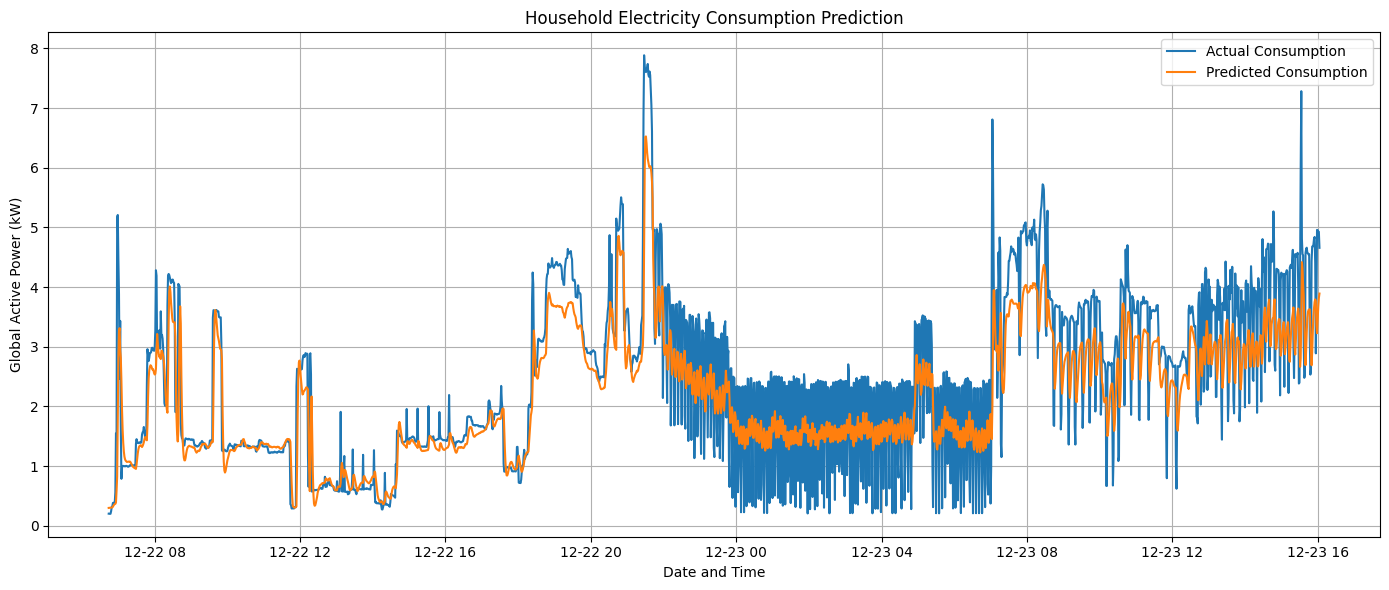

In [ ]:
test_times = df.index[split_index:]

plt.figure(figsize=(14, 6))

plt.plot(
    test_times,
    actual,
    label="Actual Consumption"
)

plt.plot(
    test_times,
    predicted,
    label="Predicted Consumption"
)

plt.title("Household Electricity Consumption Prediction")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

In [ ]:
results = pd.DataFrame({
    "Actual_kW": actual[:10],
    "Predicted_kW": predicted[:10]
}, index=test_times[:10])

print("PREDICTIONS ON UNSEEN RECORDS")
display(results.round(3))

PREDICTIONS ON UNSEEN RECORDS


,Actual_kW,Predicted_kW
datetime,,
2006-12-22 06:44:00,0.204,0.300
2006-12-22 06:45:00,0.202,0.301
2006-12-22 06:46:00,0.202,0.303
2006-12-22 06:47:00,0.202,0.305
2006-12-22 06:48:00,0.246,0.306
2006-12-22 06:49:00,0.316,0.306
2006-12-22 06:50:00,0.330,0.310
2006-12-22 06:51:00,0.384,0.321
2006-12-22 06:52:00,0.386,0.341


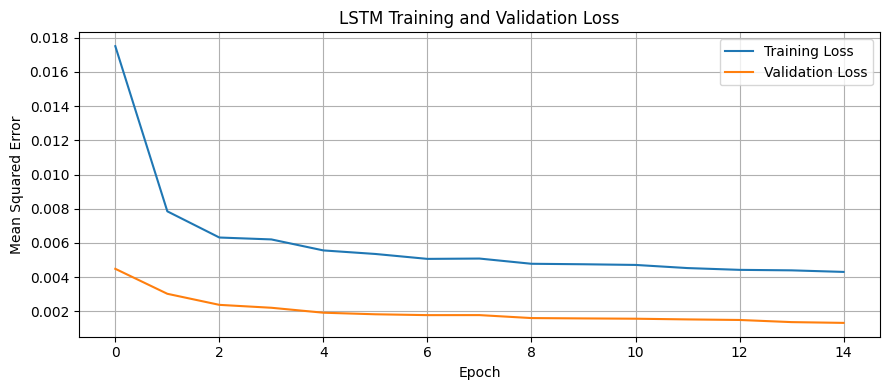

In [ ]:
plt.figure(figsize=(9, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("training_loss.png", dpi=300)
plt.show()

In [ ]:
print("FINAL MODEL RESULTS")
print("===================")
print(f"MAE  = {mae:.4f} kW")
print(f"RMSE = {rmse:.4f} kW")

FINAL MODEL RESULTS
MAE  = 0.6076 kW
RMSE = 0.7992 kW


In [ ]:
model.save("electricity_lstm.keras")
results.to_csv("sample_predictions.csv")

print("Model and prediction results saved successfully!")

Model and prediction results saved successfully!


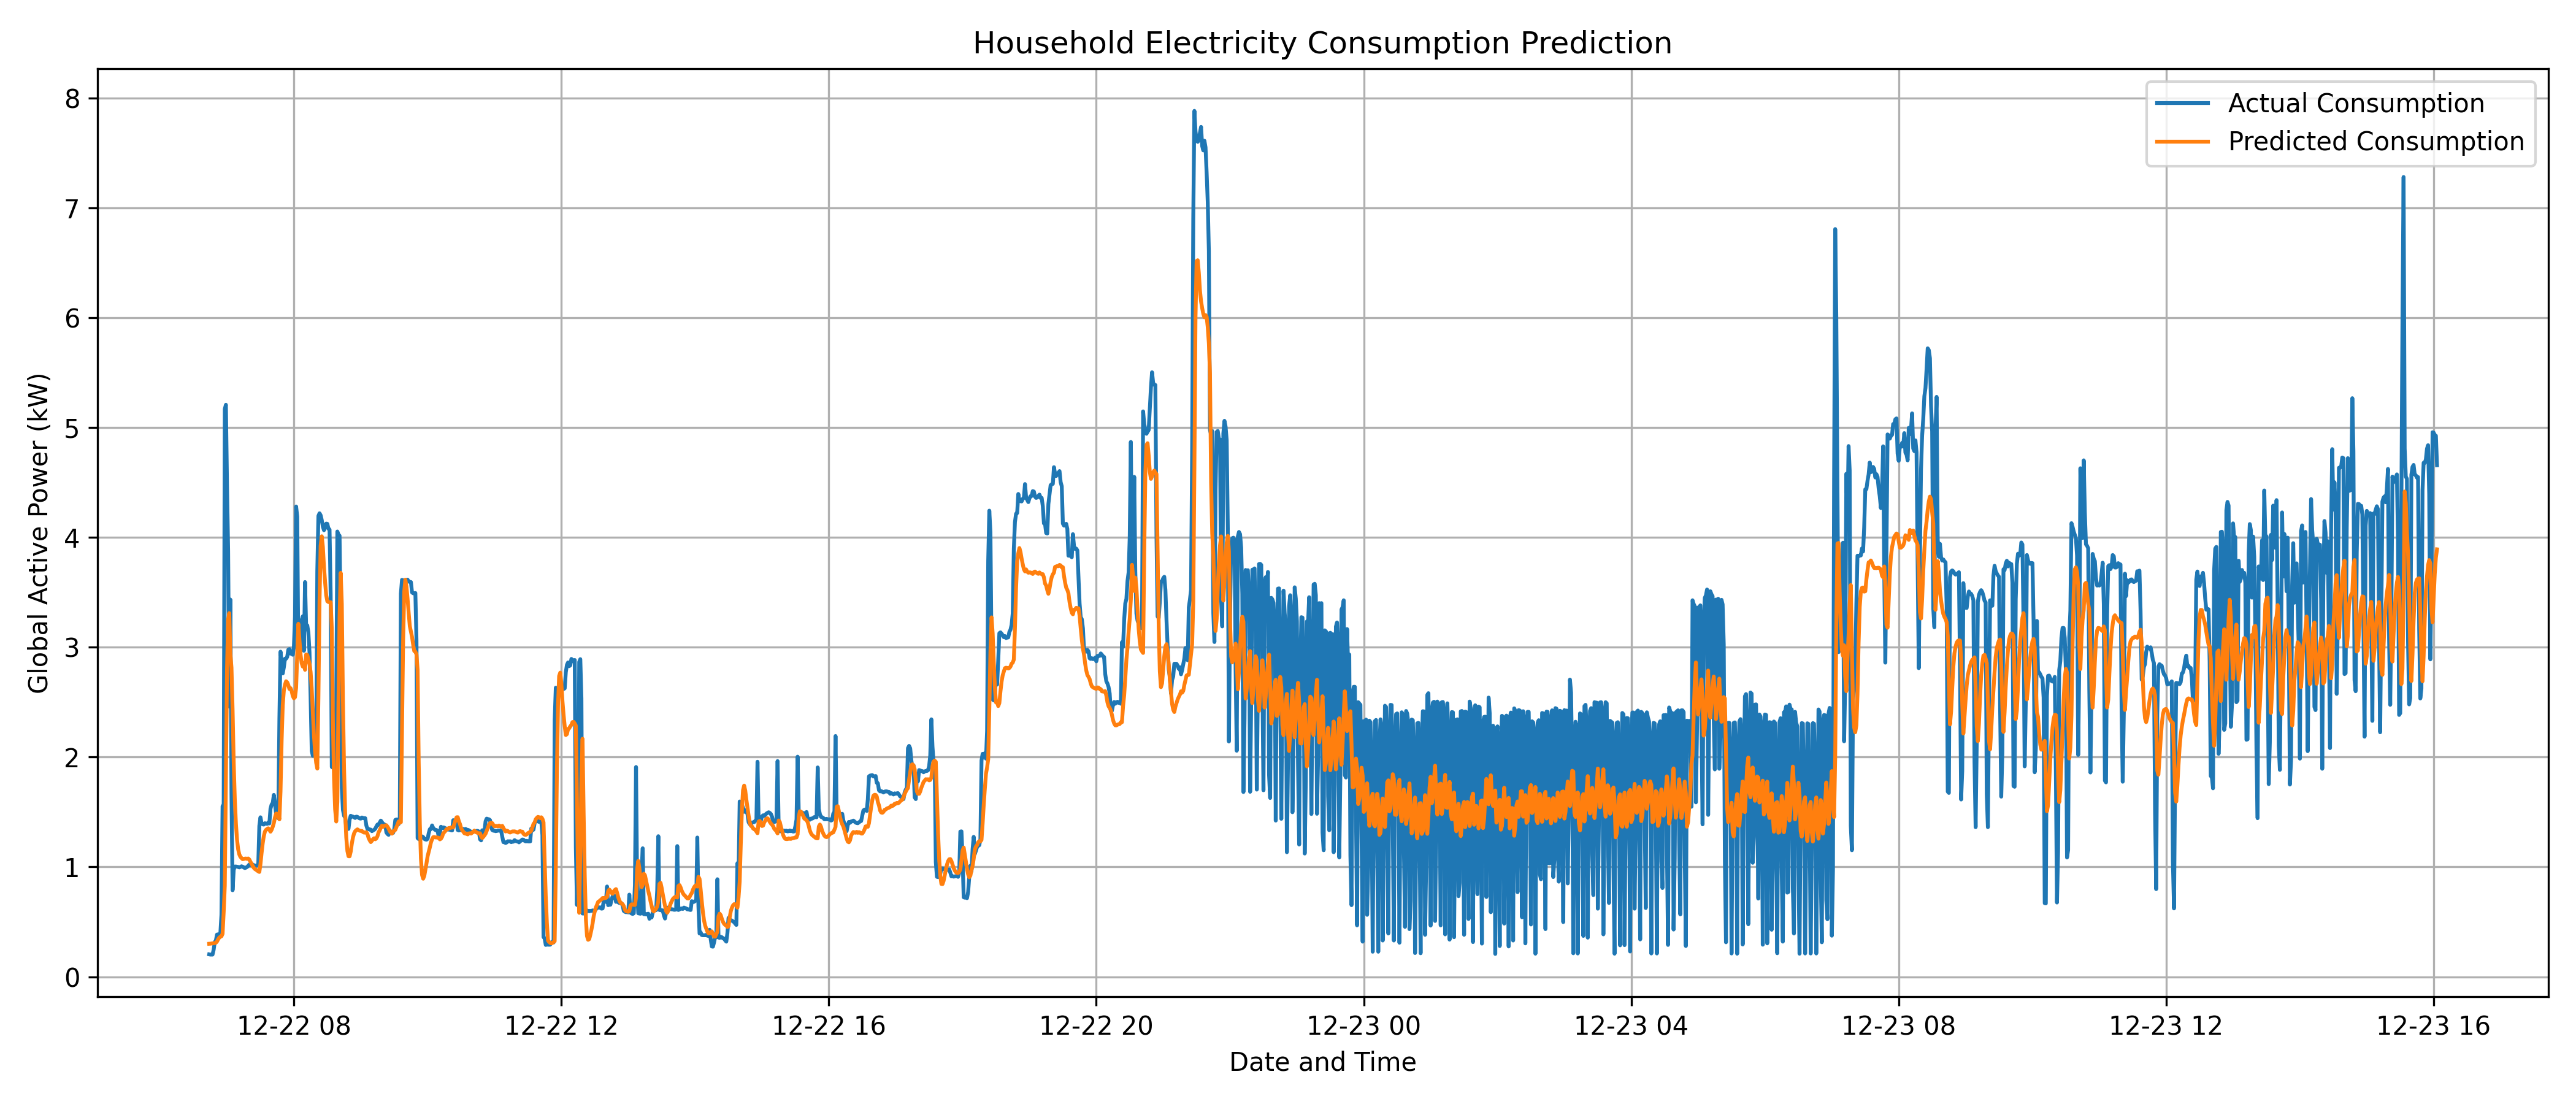

In [ ]:
from IPython.display import Image, display

display(Image(filename="actual_vs_predicted.png"))

HOUSEHOLD ELECTRICITY CONSUMPTION PREDICTION
Model: LSTM
Training records: 7940
Testing records: 2000
MAE  : 0.6076 kW
RMSE : 0.7992 kW


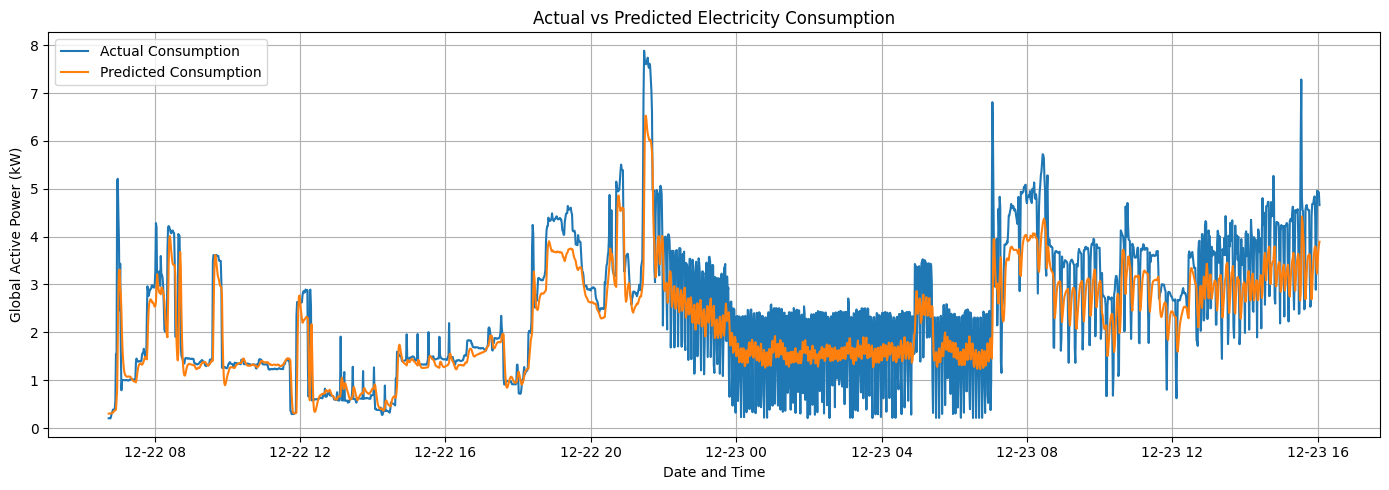

,Actual_kW,Predicted_kW
datetime,,
2006-12-22 06:44:00,0.204,0.300
2006-12-22 06:45:00,0.202,0.301
2006-12-22 06:46:00,0.202,0.303
2006-12-22 06:47:00,0.202,0.305
2006-12-22 06:48:00,0.246,0.306
2006-12-22 06:49:00,0.316,0.306
2006-12-22 06:50:00,0.330,0.310
2006-12-22 06:51:00,0.384,0.321
2006-12-22 06:52:00,0.386,0.341


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert scaled predictions back to kW
actual = scaler.inverse_transform(
    np.column_stack([
        y_test,
        np.zeros((len(y_test), len(features) - 1))
    ])
)[:, 0]

predicted = scaler.inverse_transform(
    np.column_stack([
        predicted_scaled,
        np.zeros((len(predicted_scaled), len(features) - 1))
    ])
)[:, 0]

# Calculate actual evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("HOUSEHOLD ELECTRICITY CONSUMPTION PREDICTION")
print("Model: LSTM")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"MAE  : {mae:.4f} kW")
print(f"RMSE : {rmse:.4f} kW")

# Actual vs Predicted graph
test_times = df.index[split_index:]

plt.figure(figsize=(14, 5))
plt.plot(test_times, actual, label="Actual Consumption")
plt.plot(test_times, predicted, label="Predicted Consumption")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Date and Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

# Show first 10 unseen test predictions
results = pd.DataFrame({
    "Actual_kW": actual[:10],
    "Predicted_kW": predicted[:10]
}, index=test_times[:10])

display(results.round(3))

In [ ]:

import numpy as np

# Calculate prediction accuracy percentage
actual = np.array(actual)
predicted = np.array(predicted)

denominator = np.sum(np.abs(actual))

if denominator != 0:
    accuracy = (1 - np.sum(np.abs(actual - predicted)) / denominator) * 100
    accuracy = max(0, accuracy)
    print(f"LSTM Model Accuracy: {accuracy:.2f}%")
else:
    print("Cannot calculate accuracy.")


LSTM Model Accuracy: 75.12%


In [ ]:
total_records = len(X_train) + len(X_test)

training_percentage = (len(X_train) / total_records) * 100
testing_percentage = (len(X_test) / total_records) * 100

print(f"Training Percentage: {training_percentage:.2f}%")
print(f"Testing Percentage: {testing_percentage:.2f}%")

Training Percentage: 79.88%
Testing Percentage: 20.12%
